# MODIFICAR
Avance del 23 de octubre
Mario Betancourt

# PARTE 1 - PROPUESTA
En este proyecto se diseñan e implementan algoritmos de aprendizaje por refuerzo profundo para controlar el movimiento de un robot autobalanceante. El robot en cuestión consiste de un cuerpo rígido con dos ruedas acopladas, las cuales son impulsadas por dos motores con cajas reductoras. Para medir su orientación el robot utiliza un sensor IMU (Unidad de Medición Inercial), el cual proporciona información en tiempo real de su vector de aceleración lineal, su vector de velocidad angular y el vector de campo magnético en la posición donde se encuentra ubicado. El algoritmo (físicamente programado en un microcontrolador) usa esta información para controlar el movimiento de los motores y obtener un refuerzo sí esta acción contribuya a que el robot se encuentre balanceado sobre su eje vertical. 

## 1.1. Algoritmos
Se propone comparar y el rendimiento de los cuatro algoritmos vistos durante la sesión de Deep RL parte 2: DDPG, TD3, SAC, PPO. El resultado final de esta comparación debe ser una serie de gráficas que muestren la recompensa en función del número de episodios de entrenamiento. A través de esta gráfica será posible determinar qué algoritmo *aprende más rápido* a cumplir con la tarea y, en estado estacionario, cuál termina completando la misión con el mejor rendimiento.


## 1.2. Fuentes de Incertidumbre
Una de las principales motivaciones para utilizar algoritmos de Aprendizaje por refuerzo para resolver este problema es la cantidad importante de parámetros con incertidumbres asociadas a diferencias de implementación y factores asociados con el ambiente. Se desea que si los algoritmos se implementan sobre un robot físico, estos permitan que, sin importar en qué parte del robot se coloca la IMU, este pueda balancearse a sí mismo.

## 1.3 Antecedentes
Este proyecto está inspirado por la serie de videos de Digikey y Shawn Hymel "Reinforcement Learning for Robotics" donde se implementa un robot autobalanceante con el kit M5Stack BALA2 de Digikey usando un algoritmo PPO. En este proyecto se utilizan las herramientas presentadas en la serie, y se repite con los otros algoritmos vistos en clase, con el objetivo de comparar su rendimiento en esta aplicación. También se implementa una versión física del robot.

# PARTE 2 - ENTORNO

## 2.1. Motor de Físicas MuJoCo
MuJoCo (Multi-Joint dynamics with Contact) es un motor de física de código abierto desarrollado po Google Deepmind. Este está diseñado para realizar simulaciones rápidas y precisas. Sus fortalezas principales son su simulación realista del contacto físico, el uso formatos de modelado simples y compatibles con otros motores de físicas, la inclusión de herramientas de visualización y (posiblemente la más importante), su *fácil integración con IA*. *MuJoCo se puede usar como una librería de Python y se puede integrar directamente con Gymnasium*.

Para utilizar MuJoCo en un programa de Python, es necesario descargarlo

## 2.1. Modelado 3D en CAD
MuJoCo trabaja utilizando mallas de los objetos que componen a un modelo tridimensional del robot. Estos modelos se pueden generar en softwares de diseño asistido por computadora (por sus siglas en inglés, CAD). 

La mayoría de softwares CAD de uso común en ingeniería (E.g. Solidworks, AutoCAD, Autodesk Inventor, Autodesk Fusion, CATIA, entro otros) pueden producir archivos STL (Standard Tessellation Language). El formato STL define la geometría de la superficie de un objeto 3D mediante una malla de triángulos interconectados... ¡Es justo lo que MuJoCo necesita! Por practicidad, se recomienda generar un archivo STL por cada parte con movimiento independiente en el robot. Esto se explicará con más detalle en la próxima sección.

Una observación importante acerca de los modelos de mallas es que estos se vuelven progresivamente más complicados y, por lo tanto, dificiles de utilizar en motores de físicas conforme la cantidad de detalles pequeños incrementa. Esto se debe a que en las regiones con detalles finos la cantidad de triángulos es mayor y por lo tanto se requiere un cómputo más pesado para resolver los contactos. Esto impacta, por ejemplo, en el modelado de las bandas de rodadura de las cubiertas de las ruedas. En su lugar, podemos considerar estas "deformidades" aleatorizando el dominio, como se explicará más adelante.

Respecto a la serie de videos de Shawn Hymel, en este proyecto nos omitimos el proceso de generar un diseño 3D del cuerpo del robot y las ruedas. Utilizamos los archivos STL que utilizan en la serie para importarlos directamente al entorno.

Además de los archivos STL, precisamos de información relevante sobre las propiedades físicas de los objetos que componen el robot. Por cada parte móvil del modelo simplificado, necesitamos su masa, las coordenadas de su centro de gravedad y sus momentos de inercia. Estas tres cantidades por lo general se pueden encontrar en Softwares de modelado CAD. En el proyecto original estos se obtuvieron usando la API de FreeCAD en Python, aunque conociendo el funcionamiento de otras opciones, este procedimiento podría ser incluso innecesario.

## 2.2. Formato de Modelo MuJoCo
Para definir las características del entorno de modelado, MuJoCo utiliza el formato nativo MJCF, un lenguaje basado en XML. En este archivo el usuario puede definir:
- **Uniones entre elementos**
- **Sensores y Actuadores**
- **Parámetros físicos de la simulación**: Gravedad, diferencial de tiempo
- **Visualización y Renderizado**

MuJoCo ofrece una amplia documentación respecto a cómo configurar cada uno de estos parámetros. A pesar de ello, aquí se presenta una breve introducción. 

**USO DE IA:** El esqueleto del archivo MJCF en este archivo se generó usando Gemini. Este archivo se generó al consultarle a la IA por una serie de pasos para construir el formato. Los pasos se resumen a continuación (escritos a mano). 

Observe en el archivo balancebot.xml el esqueleto del MJCF define primero parámetros del compilador (ángulo en radianes, la carpeta donde encontrar las mallas y el diferencial de tiempo máximo). Luego se configura la opción del diferencial de tiempo máximo.

La importación de archivos STL a MuJoCo se realiza dentro del bloque asset. Cada malla se importa a través de una línea <mesh ...>, donde se escribe el nombre de los ficheros y su escala. Observe que se aplica un factor de escalamiento en los tres ejes de 0.001 dado que el estandar internacional de dimensión en softwares de diseño es el milímetro. Al dividir entre 1000 se obtienen dimensiones en metros.

En worldbody se definen ambas las propiedades del entorno como del robot mismo. Observe que en geom se define la geometría del piso, donde se incluye su tamaño y su coeficiente de fricción.

El cuerpo del robot se define tramién dentro de worldbody. Observe que las *masas* del robot se representan a través <inertial> y las geometrías para colisiones son geom. Cualquier ubicación relevante, que no corresponda a una malla o un objeto con masa, puede definirse a través de una línea site. En el robot definido, hay un único site que corresponde a la ubicación física del sensor IMU, Las ruedas se acoplan al chasis del robot a través de juntas (joints). Al igual que en los eslabones de un mecanismo el tipo de junta dicta cuántos grados de libertad tiene y qué tipos de movimiento puede realizar (traslacional, rotacional o complejo). Una junta de tipo 'hinge' corresponde a una junta de bisagra, un tipo de junta que solo puede rotar alrededor de un eje.

Finalmente se define un bloque actuator, donde se definen los motores de cada rueda. Observe que entre los parametros de <motor> se incluye la razón de la caja reductora, que representa la reducción de velocidad del eje del motor al eje de salida. También se fefine el rango de control del motor.

En el bloque sensor se agregan el acelerómetro y el giroscopio en el site definido anteriormente. En este bloque también se agregan la posición y velocidad de los motores con encoders. Sin embargo, al igual que como se indica en los videos, estos últimos cuatro valores sólo existen dentro de la simulación.

## 1.3. Aspectos de Implementación que pueden cambiar
Dado que este proyecto está intencionado para poder implementar un agente con cuerpo (embodied agent), es importante hacer una observación acerca de cómo el robot puede medir el estado de movimiento de sus motores.

Para medir la posición y velocidad angular de un motor eléctrico, el método utilizado por el BALA5 de Digikey es emplear *encoders*: sensores optomecánicos con ruedas ranuradas que codifican la posición angular de un eje con estados de luz y oscuridad.

No obstante, si queremos ser más tacaños (voy a quitar esto más adelante), vale la pena hacer un pequeño cambio sobre esta parte. En un robot más simple el control de los motores se podría realizar a través de una técnica conocida como PWM. En esta el voltaje entregado a los motores se produce de forma pulsada, con un ancho de pulso que varía entre 0 hasta el periodo completo. Esto permite controlar la velocidad del motor, aunque es necesario de todas maneras un encoder para determinar el estado de los motores....





# 3. ENTORNO DE GYMNASIUM


En ´balance_bot_env.py´ el espacio de acciones se define como una caja bidimensional con valores de tipo ´float32´. Cada número representa el torque normalizado en los motores izquierdo y derecho del robot. Un número positivo indica que el motor gira en una dirección que impulsa el robot hacia adelante, mientras que un número negativo indica que el motor gira en una dirección que impulsa al robot hacia atrás.

$$\mathcal{A} = \{(l,r) \in \mathbb{R}^2 ;  |l| \leq 1; |r| \leq 1 \}$$

El espacio de estados del robot se define a través de dos mediciones relevantes de los sensores. Se tomó la decisión de que en esta implementación no se utilicen encoders de motores, por el costo incrementado que imponen sobre una realización física. Por lo tanto, el único sensor que el robot puede utilizar es el sensor IMU, que proporciona datos del vector aceleración y el vector de velocidad angular. Recuerde de sus clases de física que la aceleración traslacional puede ser integrada una vez para obtener la velocidad traslacional e integrada una segunda vez para obtener la posición traslacional. De forma similar, la velocidad angular del sensor IMU puede ser integrada una vez para obtener la posición angular. 

Se decidió modificar la implementación del código original para que el *espacio de estados* sea un vector con valores para el ángulo respecto a la vertical (pitch), la velocidad angular del robot respecto a pitch (pitch rate), la velocidad traslacional del robot y la posición del robot. Estas variables se escogieron porque pueden ayudar a definir una función de recompensa que logre dos objetivos importantes: mantenerse de pie durante un tiempo indefinidamente prolongado y responder a comandos que controlen su velocidad.

En la inicialización del entorno se define un ángulo de inclinación máximo de 30°. Si el robot se tambalea a un ángulo mayor durante un episodio de entrenamiento, el episodio termina automáticamente.

La función de recompensa se implementa en step. Se decide hacer lo siguiente:

1. La función de recompensa aplica un castigo proporcional al ángulo de inclinación en cada paso donde no se haya terminado.
2. La función de recompensa premia al robot cuando el ángulo de inclinación pitch se mantiene en un ángulo $\theta_{min} = 2\°$ respecto a la vertical.

Escribir fórmula xdd





In [2]:
from balance_bot_env import BalanceBotEnv
from gymnasium.utils.env_checker import check_env


# En esta parte del Script
env = BalanceBotEnv(mjcf_path="autobalance.xml") # Ajusta la ruta a tu archivo XML
check_env(env)
print("¡El entorno de Gymnasium cumple con los estándares correctamente!")

¡El entorno de Gymnasium cumple con los estándares correctamente!


c:\Users\mario\AppData\Local\Programs\Python\Python310\lib\site-packages\gymnasium\utils\env_checker.py:440: UserWarning: WARN: Not able to test alternative render modes due to the environment not having a spec. Try instantiating the environment through `gymnasium.make`
  logger.warn(


Una de las muchas genialidades de MuJoCo es que tiene un simulador con un Display integrado. Este puede ser instanciado usando mujoco.viewer. La siguiente celda muestra el simulador. El simulador se mantiene corriendo hasta que usted lo cierre. Para ver el simulador, descomente la última línea de código.

In [ ]:
import mujoco
import mujoco.viewer
import time

def visualizar_simulador_mujoco(mjcf_path="autobalance.xml"):
    """Abre el visor interactivo del robot y ejecuta la simulación."""
    model = mujoco.MjModel.from_xml_path(mjcf_path)
    data = mujoco.MjData(model)

    with mujoco.viewer.launch_passive(model, data) as viewer:
        while viewer.is_running():
            mujoco.mj_step(model, data)
            viewer.sync()
            time.sleep(0.005)


# DESCOMENTAR ESTA LÍNEA PARA VER SIMULADOR
# visualizar_simulador_mujoco()


Esto debería mostrar una ventana como la siguiente, donde se podrá observar al robot parado sobre el origen de coordenadas sin hacer absolutamente nada. Eventualmente el robot podrá caerse sobre sí mismo.

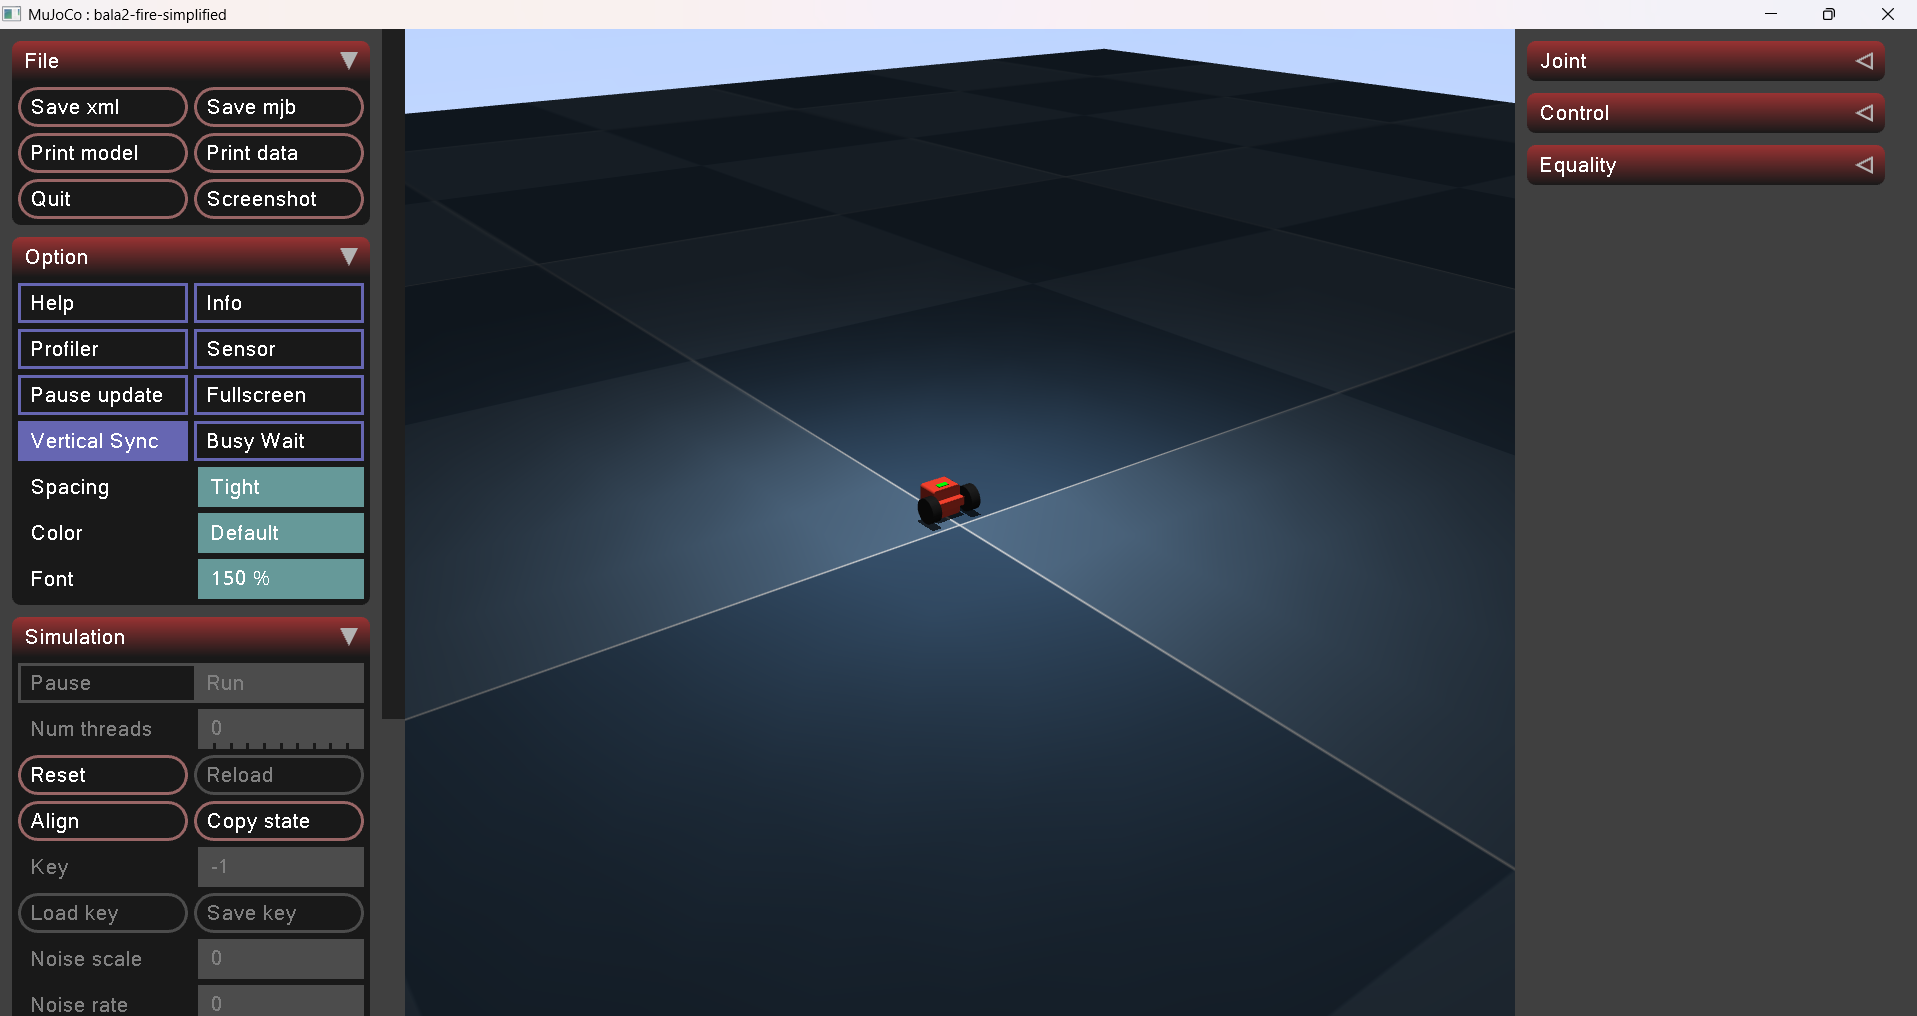

# 4. DDPG


El primer algoritmo a ser probado en este entorno es DDPG (Deep Deterministic Policy Gradient). Este es una versión mejorada de DQN que puede funcionar en dominios de espacios de acciones continuos. A diferencia de DQN, DDPG utiliza dos aproximadores de funciones para estimar la política, así como el valor de acción. Por lo tanto, DDPG es un método Actor-Critic, dado que la política generadora de comportamiento (el actor) y la política utilizada para evaluar el rendimiento del agente (el crítico, con una política equivalente al argmax en DQN) son diferentes. DDPG utiliza los mismos dos trucos que DQN usa para no fallar por la triada mortal en la mayoría de casos: target networks y experience replay. Debido a esto, DDPG utiliza *cuatro* redes neuronales, dos networks online y dos target networks. La network online contienen la política que se está entrenando.

Abajo se muestra una imagen de la arquitectura de una red DDPG. Como se puede apreciar, en ambas la red del actor y la red del crítico hay una red objetivo. La red objetivo de la acción copia los parámetros de la red online después de un número de pasos determinado. La red online proporciona una distribución mu que es recibida por l red online Q del crítico. Esta red estima el gradiente del valor de acción parametrizado. Este es recibido por el gradiente de la red online y con un optimizador, se actualizan los parámetros. Esto involucra un proceso de Policy Gradient, dado que la política mejorada (estimada por la red online del actor) se parametriza con respecto a un vector de pesos simbolo xdd y se aplica un algoritmo de ascenso por el gradiente para encontrar la dirección de máximo incremento. Esta es, de hecho, la solución en DDPG a la necesidad de reemplazar la función argmax que se usa en Q-Learning y DQN. La red neuronal del actor, por lo tanto, aprende la política óptima. 

Una pregunta que puede surgir al reflexionar sobre el funcionamiento de este algoritmo es, si las redes Online del actor y el critic hacen la mayor parte del trabajo, ¿cuál es el propósito de las redes target? La respuesta a esto es puramente por estabilidad. Se utilizan redes neuronales para estimar funciones temporalmente constantes para que el entrenamiento de las redes online sea, durante un número de pasos dado desde un principio, un problema de aprendizaje supervisado. 

El nombre DDPG resulta de que el algoritmo es básicamente una combinación de Deep-Q Network (DQN) y Deterministic Policy Gradient (DPG). 

Interesantemente en las implementaciones de Pytorch, dada la red neuronal que estima Q(s,a), no es necesario aplicar métodos iterativos para calcular las derivadas parciales de este. En su lugar, se utiliza backpropagation para calcular el gradiente de forma eficiente.

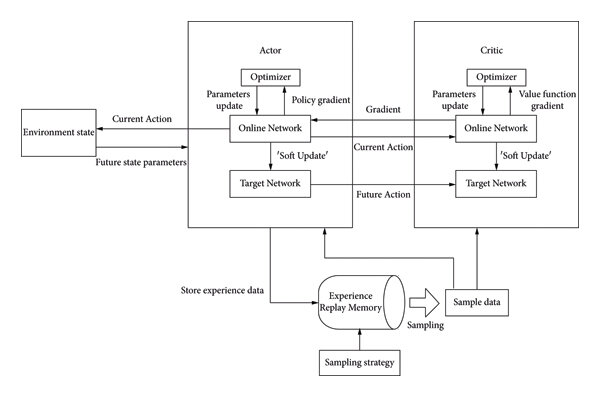

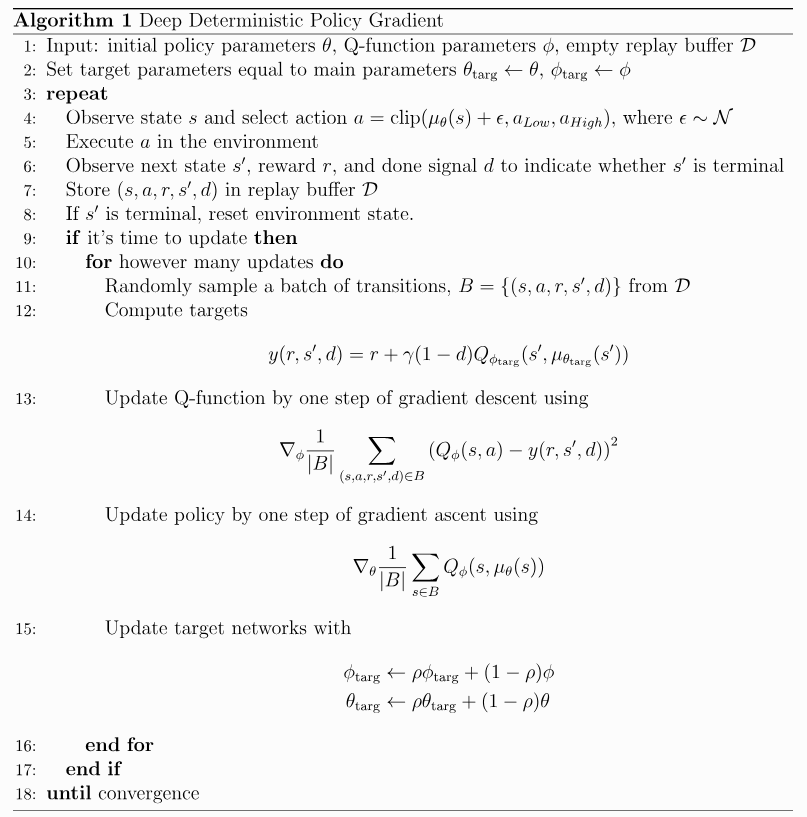

In [ ]:
'''
Hola Claude podrías implementar DDPG para este problema
'''

https://spinningup.openai.com/en/latest/algorithms/ddpg.html

# 5. PPO

El segundo algoritmo a ser implementado en este cuadernillo es PPO (Proximal Policy Optimization). Este es un algoritmo de gradiente de política on-policy que encuentra la política óptima al realizar un ascenso por el gradiente de la política en la dirección más probable. Al igual que DDPG PPO utiliza un esquema actor-critic.

Una de las diferencias más importantes entre PPO y los algoritmos basados en Q-Learning es que *PPO NO UTILIZA TARGET NETWORKS*. En la implementación que se muestra en este cuadernillo, PPO-Clip, la forma en que se resuelven los problemas de estabilidad asociados a la triada de la muerte es utilizando una función de recorte del objetivo. En esta ecuación

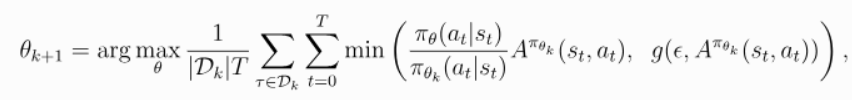

El término izquierdo representa la ventaja ponderada por muestreo por importancia, donde $pi_theta(a/s)$ representa la política actual y la del denominador (SÍMBOLO) es la política en el paso anterior. La ventaja se calcula como la diferencia entre el valor de acción y el valor de estado.

El término derecho es 
$$g(\epsilon, A) = \begin cases$$

Con una función tan extraña, vale mucho la pena cuestionar, ¿por qué esto funciona?

Una analogía (generada por Gemini preguntando si podía explicarlo como si fuesemos niños de 5 años) es la siguiente. Imagine que está aprendiendo a andar en bicicleta. Si intentamos pedalear demasiado rápido y damos un giro gigantesco de golpe podemos lastimarnos. El clip es como la mami que nos sostiene y no nos deja dar ese driftazo. Volviendo al mundo del Machine Learning, el clipeo es como ese papá o mamá que nos detiene de dar pasos demasiado grandes. 

Para continuar indagando en cómo funciona PPO, recordemos que la actualización se hace a través de una razón de probabilidades. Más formalmente, es una razón de políticas que nos dan la probabilidad (o densidad de probabilidad) de escoger una acción determinada dado un estado. Cuando tomamos una buena acción en un estado con una política nueva, el numerador del cociente incrementa para esa acción, dado que es más probable que el agente la escoja de nuevo. En cambio, si el robot hace algo malo, la probabilidad de que la escoja en el futuro disminuye, y por lo tanto el denominador incrementa. El problema surge cuando estos incrementos son tan grandes que el algoritmo olvida lo que aprendió previamente. Esto se debe, básicamente, el algoritmo le mete el pie completo al pedal y se va por un precipicio, haciendo que nunca alcance su objetivo.

Los cocientes son malvados


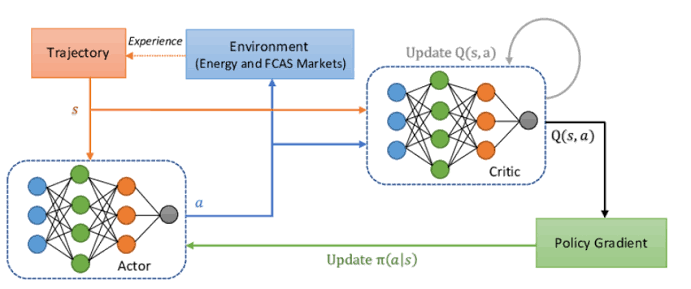

Una genialidad de PPO es que es un algoritmo altamente optimizado para implementarse con herramientas de Deep Learning, especialmente en Python. Las librerías Tensorflow y Pytorch están optimizadas para calcular gradientes analíticos, por backpropagation (algo que debo investigar con más detalle antes de la presentación), lo cual eficientiza considerablemente la evaluación de estos. 

Como se puede apreciar en el pseudocódigo de PPO-Clip, después de modificar los parámetros de las redes del actor y el crítico, se utiliza un algoritmo de stochastic gradient ascent con Adam (actor) y un algoritmo de gradient descent (crítico).

En la práctica estas fórmulas no se implementan línea por línea (a menos que queramos programar desde cero). Las librerías de Python para Deep Learning ya contienen **optimizadores** especializados para minimizar las funciones de costo. Por tales razones, las librerías de Python funcan bien para realizar descensor de gradiente, pero no al revés. Esto es importante para la red del actor, la cual necesita de un algoritmo de ascenso por el gradiente. Una solución sencillisima a este problema es invirtiendo el signo de la función costo... y sólo así el problema de buscar un mínimo se convierte en un problema de hallar un máximo.

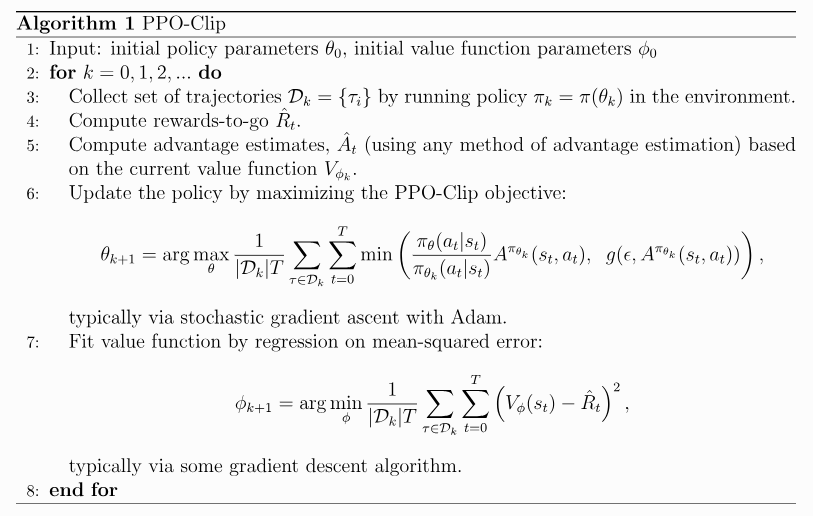

https://spinningup.openai.com/en/latest/algorithms/ppo.html

In [ ]:
'''
Hola Claude. Podrías implementar un
bloque de código para entrenar un agente PPO
usando el entorno de Gymnasium definido en balance_bot_env.py

Usa una estructura similar a la mostrada en el pseudocódigo.
'''

KeyboardInterrupt: 

: 

# 6. Entrenamiento
Finalmente, llegamos al momento de la verdad: vamos a generar instancias de los dos algoritmos implementados en este cuadernillo

## 4.1. Aprendizaje por currículos
El **Aprendizaje por Currículos** es una técnica utilizada en aprendizaje por refuerzo donde un agente aprende el comportamiento deseado en etapas de entrenamiento con una complejidad progresivamente más alta. En este caso